In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df_raw = pd.read_csv("../results/timings.csv")

In [5]:
df = df_raw[df_raw['session_id'] == "a2ac476ea8ec"] # filter to experiments session
df = df[df['index_type'] == 'sorted_list'] # filter to only sorted index types

## E1

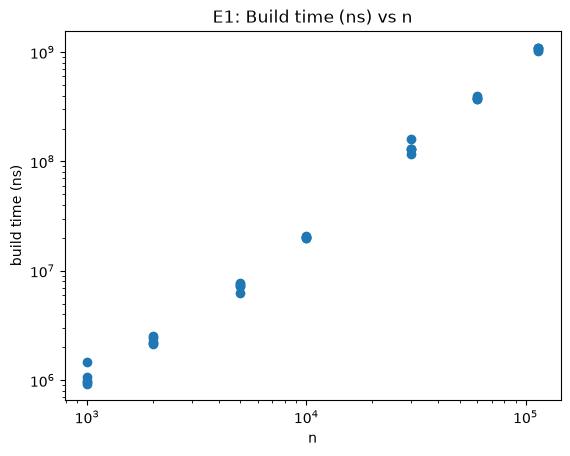

In [6]:
e1 = df[df['experiment'] == 'E1_build_track_id']

plt.loglog(e1['n_keys'], e1['total_ns'], 'o')
plt.xlabel('n')
plt.ylabel('build time (ns)')
plt.title('E1: Build time (ns) vs n')
plt.show()

## E2

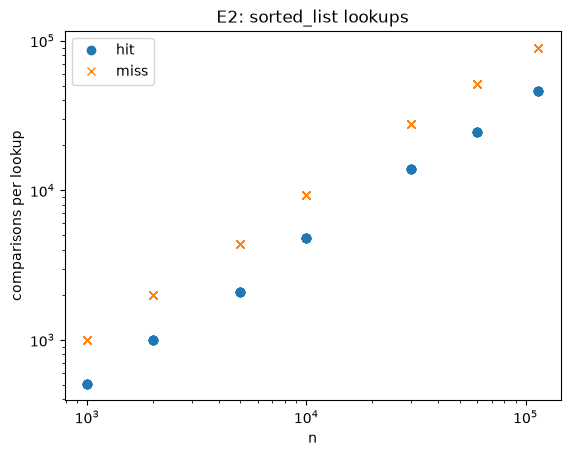

In [11]:
e2 = df[df['experiment'] == 'E2_point_track_id']
hit = e2[e2['operation'] == 'point_hit']
miss = e2[e2['operation'] == 'point_miss']

plt.loglog(hit['n_keys'], hit['comparisons'] / hit['n_ops'], 'o', label='hit')
plt.loglog(miss['n_keys'], miss['comparisons'] / miss['n_ops'], 'x', label='miss')
plt.xlabel('n')
plt.ylabel('comparisons per lookup')
plt.title('E2: sorted_list lookups')
plt.legend()
plt.show()

## E3

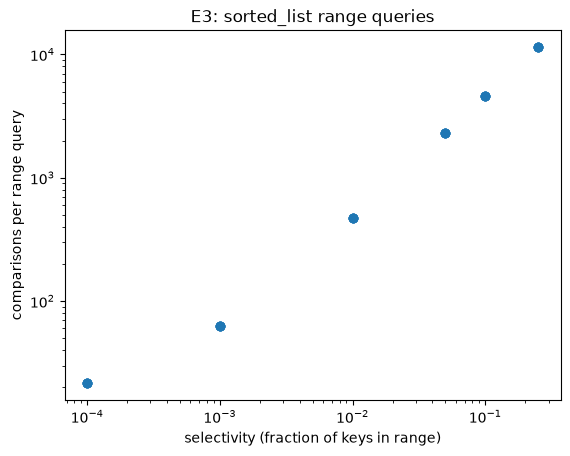

In [12]:
e3 = df[df['experiment'] == 'E3_range_tempo']

plt.loglog(e3['operation_param'], e3['comparisons'] / e3['n_ops'], 'o')
plt.xlabel('selectivity (fraction of keys in range)')
plt.ylabel('comparisons per range query')
plt.title('E3: sorted_list range queries')
plt.show()

## E4

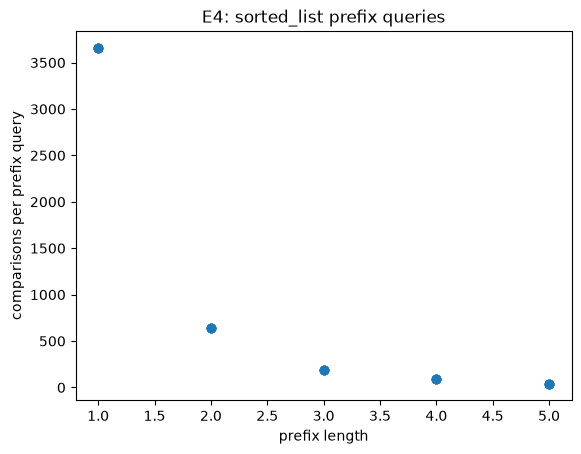

In [13]:
e4 = df[df['experiment'] == 'E4_prefix_track_name']

plt.plot(e4['operation_param'], e4['comparisons'] / e4['n_ops'], 'o')
plt.xlabel('prefix length')
plt.ylabel('comparisons per prefix query')
plt.title('E4: sorted_list prefix queries')
plt.show()

## E5

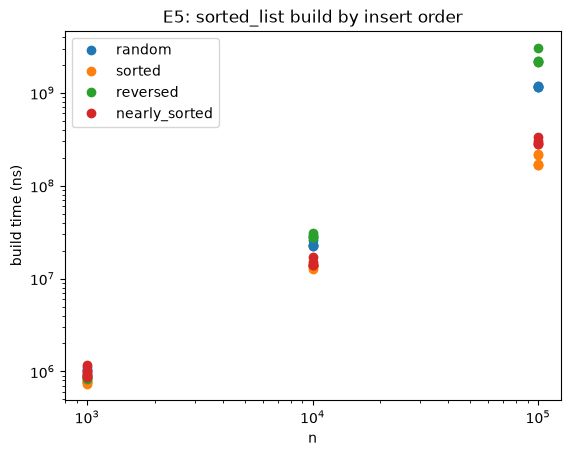

In [14]:
e5 = df[df['experiment'] == 'E5_insert_order']
build = e5[e5['operation'] == 'build']

for order in ['random', 'sorted', 'reversed', 'nearly_sorted']:
    b = build[build['insert_order'] == order]
    plt.loglog(b['n_keys'], b['total_ns'], 'o', label=order)

plt.xlabel('n')
plt.ylabel('build time (ns)')
plt.title('E5: sorted_list build by insert order')
plt.legend()
plt.show()